In [41]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

df = pd.read_csv("heart.csv")

In [42]:
df.head()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,63,1,3,145,233,1,0,150,0,2.3,0,0,1,1
1,37,1,2,130,250,0,1,187,0,3.5,0,0,2,1
2,41,0,1,130,204,0,0,172,0,1.4,2,0,2,1
3,56,1,1,120,236,0,1,178,0,0.8,2,0,2,1
4,57,0,0,120,354,0,1,163,1,0.6,2,0,2,1


In [43]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 303 entries, 0 to 302
Data columns (total 14 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       303 non-null    int64  
 1   sex       303 non-null    int64  
 2   cp        303 non-null    int64  
 3   trestbps  303 non-null    int64  
 4   chol      303 non-null    int64  
 5   fbs       303 non-null    int64  
 6   restecg   303 non-null    int64  
 7   thalach   303 non-null    int64  
 8   exang     303 non-null    int64  
 9   oldpeak   303 non-null    float64
 10  slope     303 non-null    int64  
 11  ca        303 non-null    int64  
 12  thal      303 non-null    int64  
 13  target    303 non-null    int64  
dtypes: float64(1), int64(13)
memory usage: 33.3 KB


In [44]:
df.columns

Index(['age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', 'thalach',
       'exang', 'oldpeak', 'slope', 'ca', 'thal', 'target'],
      dtype='object')

In [45]:
df.shape

(303, 14)

In [46]:
df.describe()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
count,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000
mean,54.366337,0.683168,0.966997,131.623762,246.264026,0.148515,0.528053,149.646865,0.326733,1.039604,1.399340,0.729373,2.313531,0.544554
std,9.082101,0.466011,1.032052,17.538143,51.830751,0.356198,0.525860,22.905161,0.469794,1.161075,0.616226,1.022606,0.612277,0.498835
min,29.000000,0.000000,0.000000,94.000000,126.000000,0.000000,0.000000,71.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,47.500000,0.000000,0.000000,120.000000,211.000000,0.000000,0.000000,133.500000,0.000000,0.000000,1.000000,0.000000,2.000000,0.000000
50%,55.000000,1.000000,1.000000,130.000000,240.000000,0.000000,1.000000,153.000000,0.000000,0.800000,1.000000,0.000000,2.000000,1.000000
75%,61.000000,1.000000,2.000000,140.000000,274.500000,0.000000,1.000000,166.000000,1.000000,1.600000,2.000000,1.000000,3.000000,1.000000
max,77.000000,1.000000,3.000000,200.000000,564.000000,1.000000,2.000000,202.000000,1.000000,6.200000,2.000000,4.000000,3.000000,1.000000


In [47]:
df.duplicated().sum()

np.int64(1)

<Axes: xlabel='cp'>

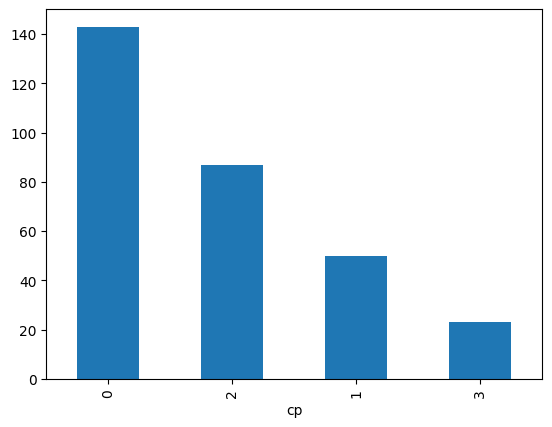

In [48]:
df['cp'].value_counts().plot(kind = 'bar')

In [49]:
df.isnull().sum()

,0
age,0
sex,0
cp,0
trestbps,0
chol,0
fbs,0
restecg,0
thalach,0
exang,0
oldpeak,0


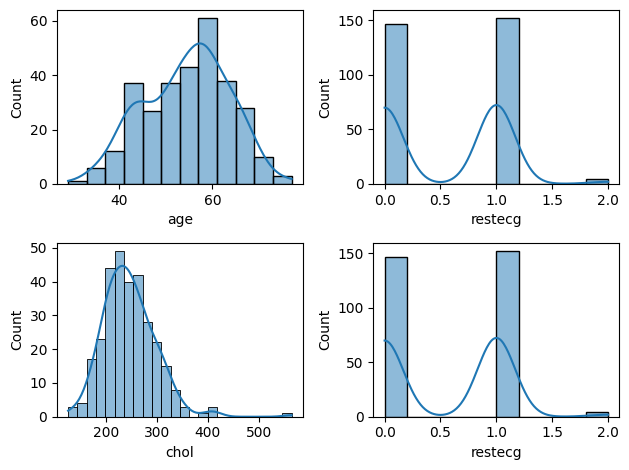

In [50]:
def plotting(var,num):
    plt.subplot(2,2,num)
    sns.histplot(df[var],kde = True)

plotting("age",1)
plotting("restecg",2)
plotting("chol",3)
plotting("restecg",4)

plt.tight_layout()

In [51]:
cholesterol_mean = df.loc[df['chol'] != 0, 'chol'].mean()

# Step 2: Replace 0s with the calculated mean
df['chol'] = df['chol'].replace(0, cholesterol_mean)

# Optional: Round to 2 decimal places (if needed)
df['chol'] = df['chol'].round(2)
resting_bp_mean = df.loc[df['restecg'] != 0, 'restecg'].mean()

df['restecg'] = df['restecg'].replace(0, resting_bp_mean)

df['restecg'] = df['restecg'].round(2)

In [52]:
df.head()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,63,1,3,145,233,1,1.03,150,0,2.3,0,0,1,1
1,37,1,2,130,250,0,1.00,187,0,3.5,0,0,2,1
2,41,0,1,130,204,0,1.03,172,0,1.4,2,0,2,1
3,56,1,1,120,236,0,1.00,178,0,0.8,2,0,2,1
4,57,0,0,120,354,0,1.00,163,1,0.6,2,0,2,1


In [53]:
df_encoded = pd.get_dummies(df,drop_first=True)
df_encoded

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,63,1,3,145,233,1,1.03,150,0,2.3,0,0,1,1
1,37,1,2,130,250,0,1.00,187,0,3.5,0,0,2,1
2,41,0,1,130,204,0,1.03,172,0,1.4,2,0,2,1
3,56,1,1,120,236,0,1.00,178,0,0.8,2,0,2,1
4,57,0,0,120,354,0,1.00,163,1,0.6,2,0,2,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
298,57,0,0,140,241,0,1.00,123,1,0.2,1,0,3,0
299,45,1,3,110,264,0,1.00,132,0,1.2,1,0,3,0
300,68,1,0,144,193,1,1.00,141,0,3.4,1,2,3,0
301,57,1,0,130,131,0,1.00,115,1,1.2,1,1,3,0


In [54]:
df_encoded = df_encoded.astype(int)
df_encoded

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,63,1,3,145,233,1,1,150,0,2,0,0,1,1
1,37,1,2,130,250,0,1,187,0,3,0,0,2,1
2,41,0,1,130,204,0,1,172,0,1,2,0,2,1
3,56,1,1,120,236,0,1,178,0,0,2,0,2,1
4,57,0,0,120,354,0,1,163,1,0,2,0,2,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
298,57,0,0,140,241,0,1,123,1,0,1,0,3,0
299,45,1,3,110,264,0,1,132,0,1,1,0,3,0
300,68,1,0,144,193,1,1,141,0,3,1,2,3,0
301,57,1,0,130,131,0,1,115,1,1,1,1,3,0


In [55]:
df_encoded.columns

Index(['age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', 'thalach',
       'exang', 'oldpeak', 'slope', 'ca', 'thal', 'target'],
      dtype='object')

In [64]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix,f1_score
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB

In [65]:
X = df_encoded.drop('target',axis=1)
y = df_encoded['target']

In [66]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [67]:
scaler = StandardScaler()
x_train_scaled = scaler.fit_transform(X_train)
x_test_scaled = scaler.transform(X_test)

In [68]:
models={
    "Logistic Regression": LogisticRegression(),
    "Decision Tree": DecisionTreeClassifier(),
    "Support Vector Machine": SVC(kernel="rbf"),
    "KNN": KNeighborsClassifier(),
    "Naive Bayes": GaussianNB()

}
result=[]

In [69]:
for name,model in models.items():
    model.fit(x_train_scaled,y_train)
    y_pred = model.predict(x_test_scaled)
    accuracy = accuracy_score(y_test,y_pred)
    print(f"Accuracy of {name}: {accuracy}")
    f1 = f1_score(y_test,y_pred)
    print(f"F1 Score of {name}: {f1}")
    result.append({
        "model": name,
        "accuracy": round(accuracy,4),
        "f1_score": round(f1,4)
    }
    )


Accuracy of Logistic Regression: 0.8688524590163934
F1 Score of Logistic Regression: 0.875
Accuracy of Decision Tree: 0.8360655737704918
F1 Score of Decision Tree: 0.8275862068965517
Accuracy of Support Vector Machine: 0.8852459016393442
F1 Score of Support Vector Machine: 0.8852459016393442
Accuracy of KNN: 0.8852459016393442
F1 Score of KNN: 0.8852459016393442
Accuracy of Naive Bayes: 0.8688524590163934
F1 Score of Naive Bayes: 0.875


In [71]:
import joblib

# Correctly pass the dictionary value and the filename as two separate arguments
joblib.dump(models['KNN'], 'KNN_heart.pkl')
joblib.dump(scaler, 'scaler.pkl')

# Call the to_list() method with parentheses
joblib.dump(X.columns.to_list(), 'columns.pkl')

['columns.pkl']